# Methodologies Notebook

1) Nx Graph Creation 
2) Transformation from Cyclic Graphs to Tiered DAGs

node: 0, power: ['medium', 'low'], roles: ['A']
node: 1, power: ['medium', 'high'], roles: ['A']
node: 2, power: ['medium', 'high'], roles: ['A']
node: 3, power: ['low', 'high'], roles: ['A']
node: 4, power: ['medium', 'low'], roles: ['A']
node: 5, power: ['medium', 'high'], roles: ['A']
node: 6, power: ['medium', 'high'], roles: ['A', 'B']
node: 7, power: ['low', 'high'], roles: ['A', 'B']
node: 8, power: ['high', 'medium'], roles: ['A', 'B']
node: 9, power: ['low', 'high'], roles: ['A', 'B']
node: 10, power: ['high', 'medium'], roles: ['A', 'B']
node: 11, power: ['medium', 'low'], roles: ['A', 'B', 'C']
node: 12, power: ['high', 'low'], roles: ['A', 'B', 'C']
node: 13, power: ['medium', 'high'], roles: ['A', 'B', 'C']
node: 16, power: ['low', 'medium'], roles: ['B', 'C']
node: 17, power: ['medium', 'low'], roles: ['B', 'C']
node: 18, power: ['medium', 'low'], roles: ['B', 'C']
node: 19, power: ['medium', 'low'], roles: ['B', 'C']
node: 20, power: ['medium', 'low'], roles: ['B', 'C']


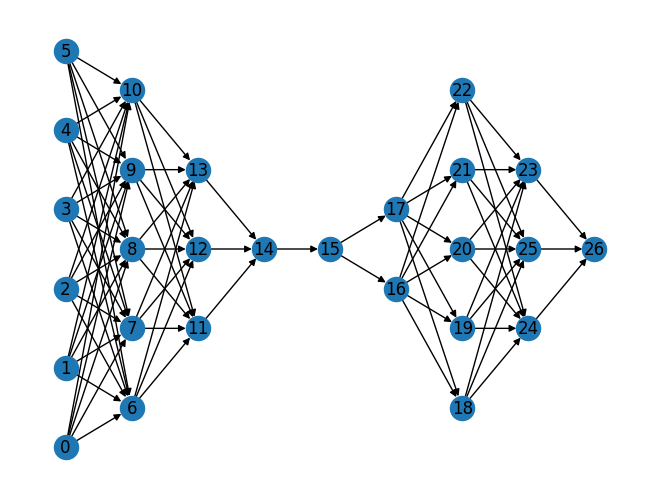

In [4]:
import numpy as np
import networkx as nx
from tqdm import trange
from collections import defaultdict
from src.graph_utils import assign_properties, create_layered_graph



layer_sizes = [6, 5, 3, 1, 1, 2, 5, 3, 1]
G, layers = create_layered_graph(layer_sizes)
pos = nx.multipartite_layout(G, subset_key='layer', align='vertical', scale=2)
layer_role_assign = {0: ['A'], 1: ['A', 'B'], 2: ['A', 'B', 'C'], 3: ['A', 'B', 'C'], 4: ['A', 'B', 'C'], 5: ['B', 'C'], 6: ['B', 'C'], 7: ['C'], 8: ['C']}
G = assign_properties(G, layer_sizes, layer_role_assign=layer_role_assign)
nx.draw(G, pos, with_labels=True, node_size=300)

In [4]:
G.nodes(data=True)

NodeDataView({0: {'layer': 0, 'demand': -2, 'probability1': 0.9534548714271365, 'probability2': 0.7212319186342562, 'cost': 1, 'loc_region': (-5, 5), 'loc': (-3.0365167225543366, 4.09873897427919), 'power': ['high', 'medium'], 'role': ['A']}, 1: {'layer': 0, 'demand': -3, 'probability1': 0.6143403003781588, 'probability2': 0.8550727530494517, 'cost': 1, 'loc_region': (-5, 5), 'loc': (2.5384003873853285, 2.4520542608415186), 'power': ['low', 'medium'], 'role': ['A']}, 2: {'layer': 0, 'demand': -3, 'probability1': 0.6936659593479203, 'probability2': 0.7097391476299604, 'cost': 4, 'loc_region': (-5, 5), 'loc': (0.30455986091583487, 1.0072314302502825), 'power': ['low', 'high'], 'role': ['A']}, 3: {'layer': 0, 'demand': -2, 'probability1': 0.7713520258952, 'probability2': 0.8144514064288972, 'cost': 7, 'loc_region': (-5, 5), 'loc': (-2.041326693567682, 0.44351685690148557), 'power': ['high', 'low'], 'role': ['A']}, 4: {'layer': 0, 'demand': -1, 'probability1': 0.9508845725998577, 'probabil

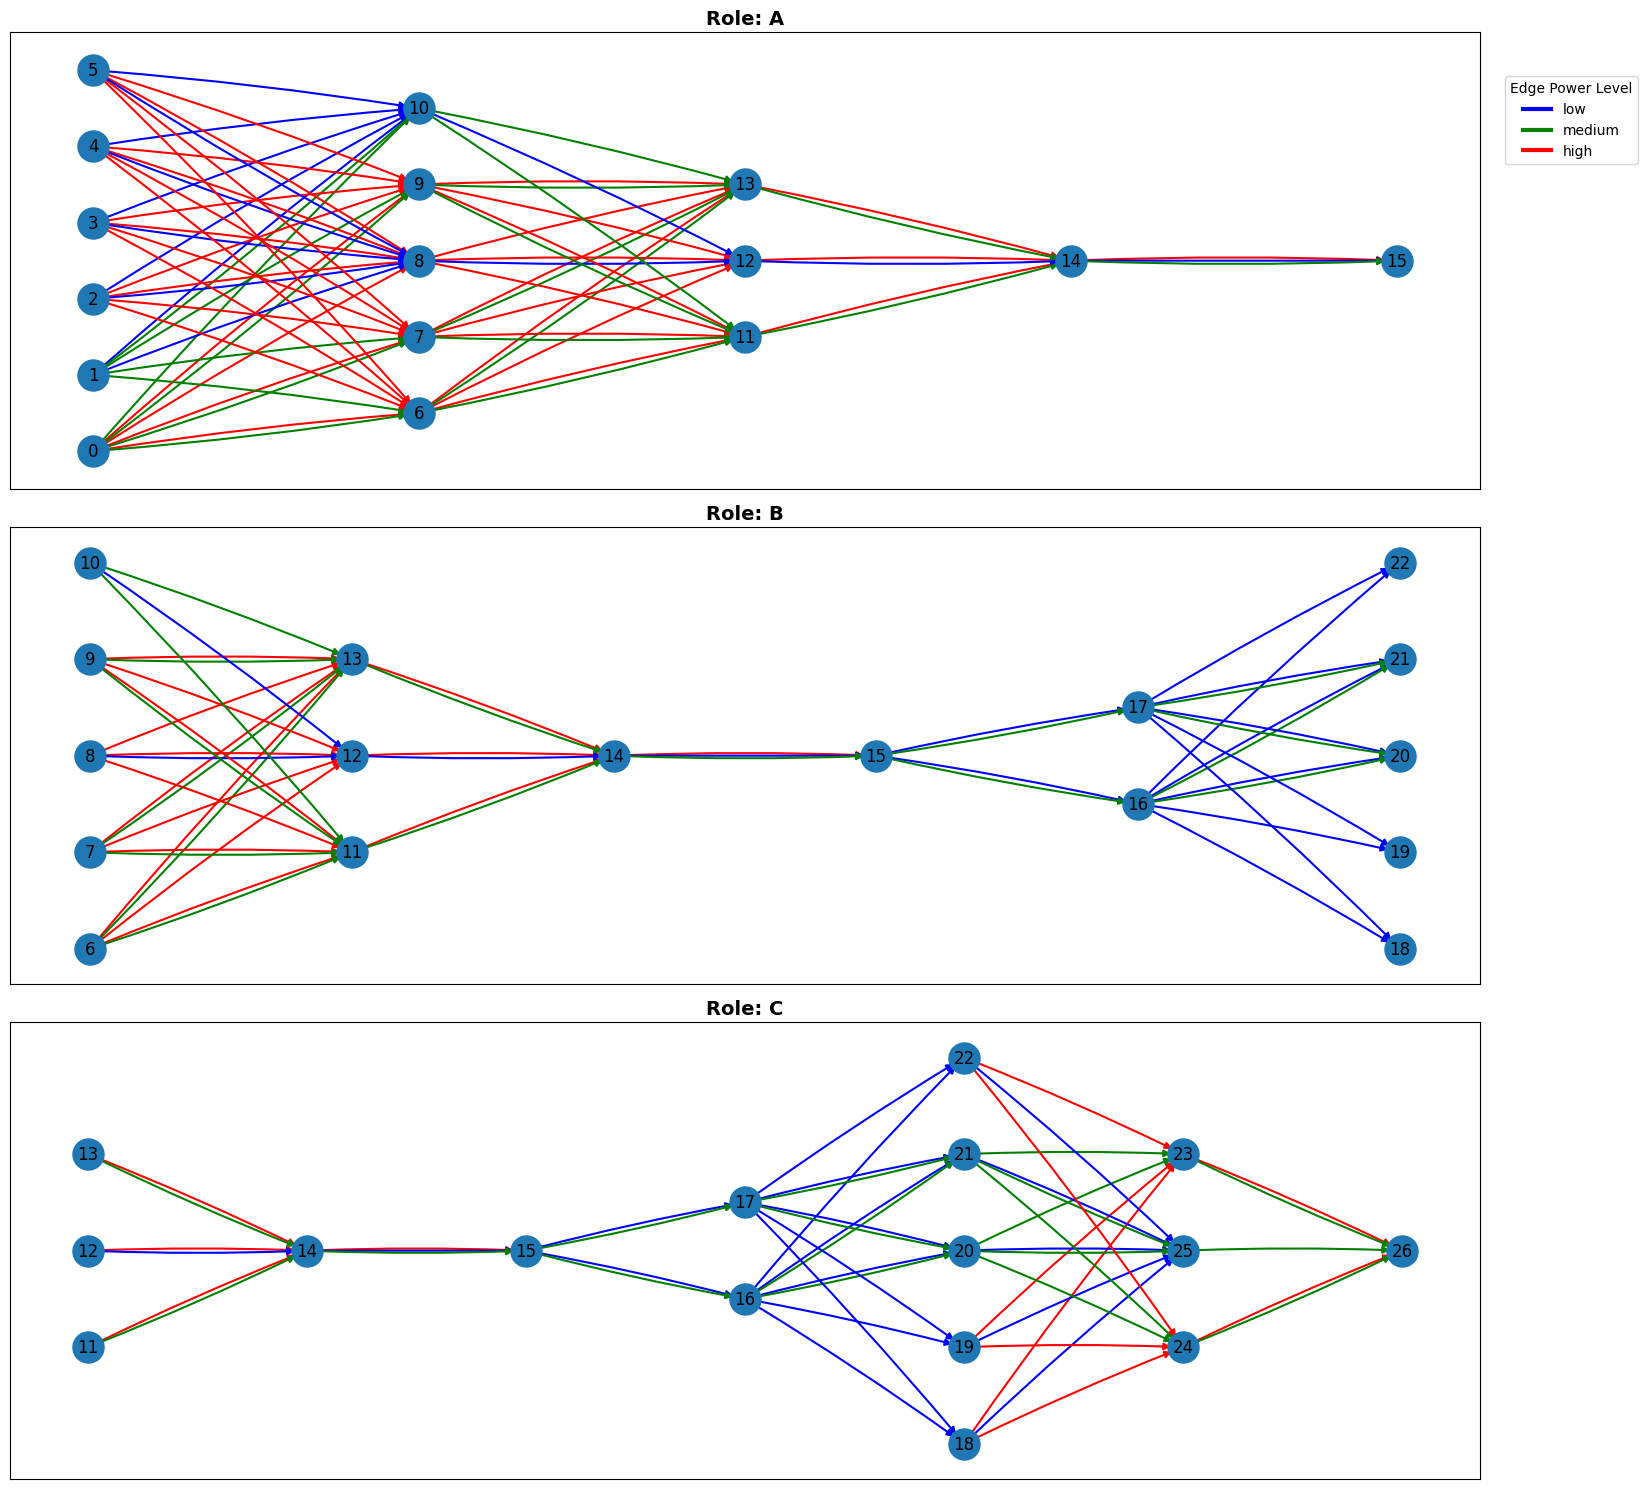

In [5]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
def draw_power_edges(subgraph, pos, ax):

    POWER_COLORS = {"low": "blue","medium": "green","high": "red"}
    legend_used = set()
    for u, v, _ in subgraph.edges(data=True):
        u_power = set(subgraph.nodes[u].get("power", []))
        v_power = set(subgraph.nodes[v].get("power", []))
        shared = sorted(u_power & v_power)
        if not shared:
            shared = ["none"]
        radii = np.linspace(-0.02, 0.02, len(shared))
        for radius, power in zip(radii, shared):
            color = (POWER_COLORS[power]if power in POWER_COLORS else "gray")
            label = None
            if power not in legend_used:
                label = power
                legend_used.add(power)
            nx.draw_networkx_edges(
                subgraph, pos,edgelist=[(u, v)],edge_color=color,width=1.5,
                connectionstyle=f"arc3,rad={radius}",ax=ax,label=label
            )
    return legend_used

def draw_role_graphs(G):
    roles = sorted(list(set(role for n in G.nodes() for role in G.nodes[n]["role"])))
    pos = nx.multipartite_layout(G, subset_key="layer", align="vertical", scale=2)
    fig, axes = plt.subplots(len(roles), 1, figsize=(15, 15))
    if len(roles) == 1:
        axes = [axes]
    for ax, role in zip(axes, roles):
        subgraph = G.subgraph(n for n in G.nodes() if role in G.nodes[n]["role"])
        pos_sub = {n: pos[n] for n in subgraph.nodes()}
        _ = draw_power_edges(subgraph, pos_sub, ax)
        #nx.draw(subgraph,pos_sub,with_labels=True,node_size=500,ax=ax)
        nx.draw_networkx_nodes(subgraph, pos_sub, node_size=500, ax=ax)
        nx.draw_networkx_labels(subgraph, pos_sub, ax=ax)

        ax.set_title(f"Role: {role}", fontsize=14, fontweight="bold")
    legend_handles = [
    Line2D([0], [0], color="blue",  lw=3, label="low"),
    Line2D([0], [0], color="green", lw=3, label="medium"),
    Line2D([0], [0], color="red",   lw=3, label="high"),
    ]   
    fig.legend(handles=legend_handles, loc="upper right", bbox_to_anchor=(1.1, 0.95), title="Edge Power Level")
    plt.tight_layout()
    plt.show()

draw_role_graphs(G)

## Flow Simulation 
- MF type problems: Where are bottlenecks? Maximum capability to deliver 
- Provides edge and node constraints 
Outputs are: 
- Expected flow
- P(demand satisfied)
- Critically of nodes

## Complete flow
Bernoulli trials for each node/edge
Does path exist?

## Performance 
- Best path
- Expected delivery quant
- Sensitive to degradation 


## Agent based simulation 
A generates resources
Resources move
B transforms 
C consumes

- Accumulation 
- Queue lengths
- Latency 

## LSCDP-type disruption 
- Number of paths
- Max flow
- Demand satisfaction 
 - Binary success
 - Random Failure
 - Targeted Degree Attack
 - Highest layer attack

 ## Cascading Failures 
 Interdiction --> increased bottlenecks
 - What are the newly stressed chains

 ## Time based modelling
 ### Events:

- arrivals
- failures
- repairs
- demand generation

### Metrics:

- queue length
- utilization
- latency
- throughput

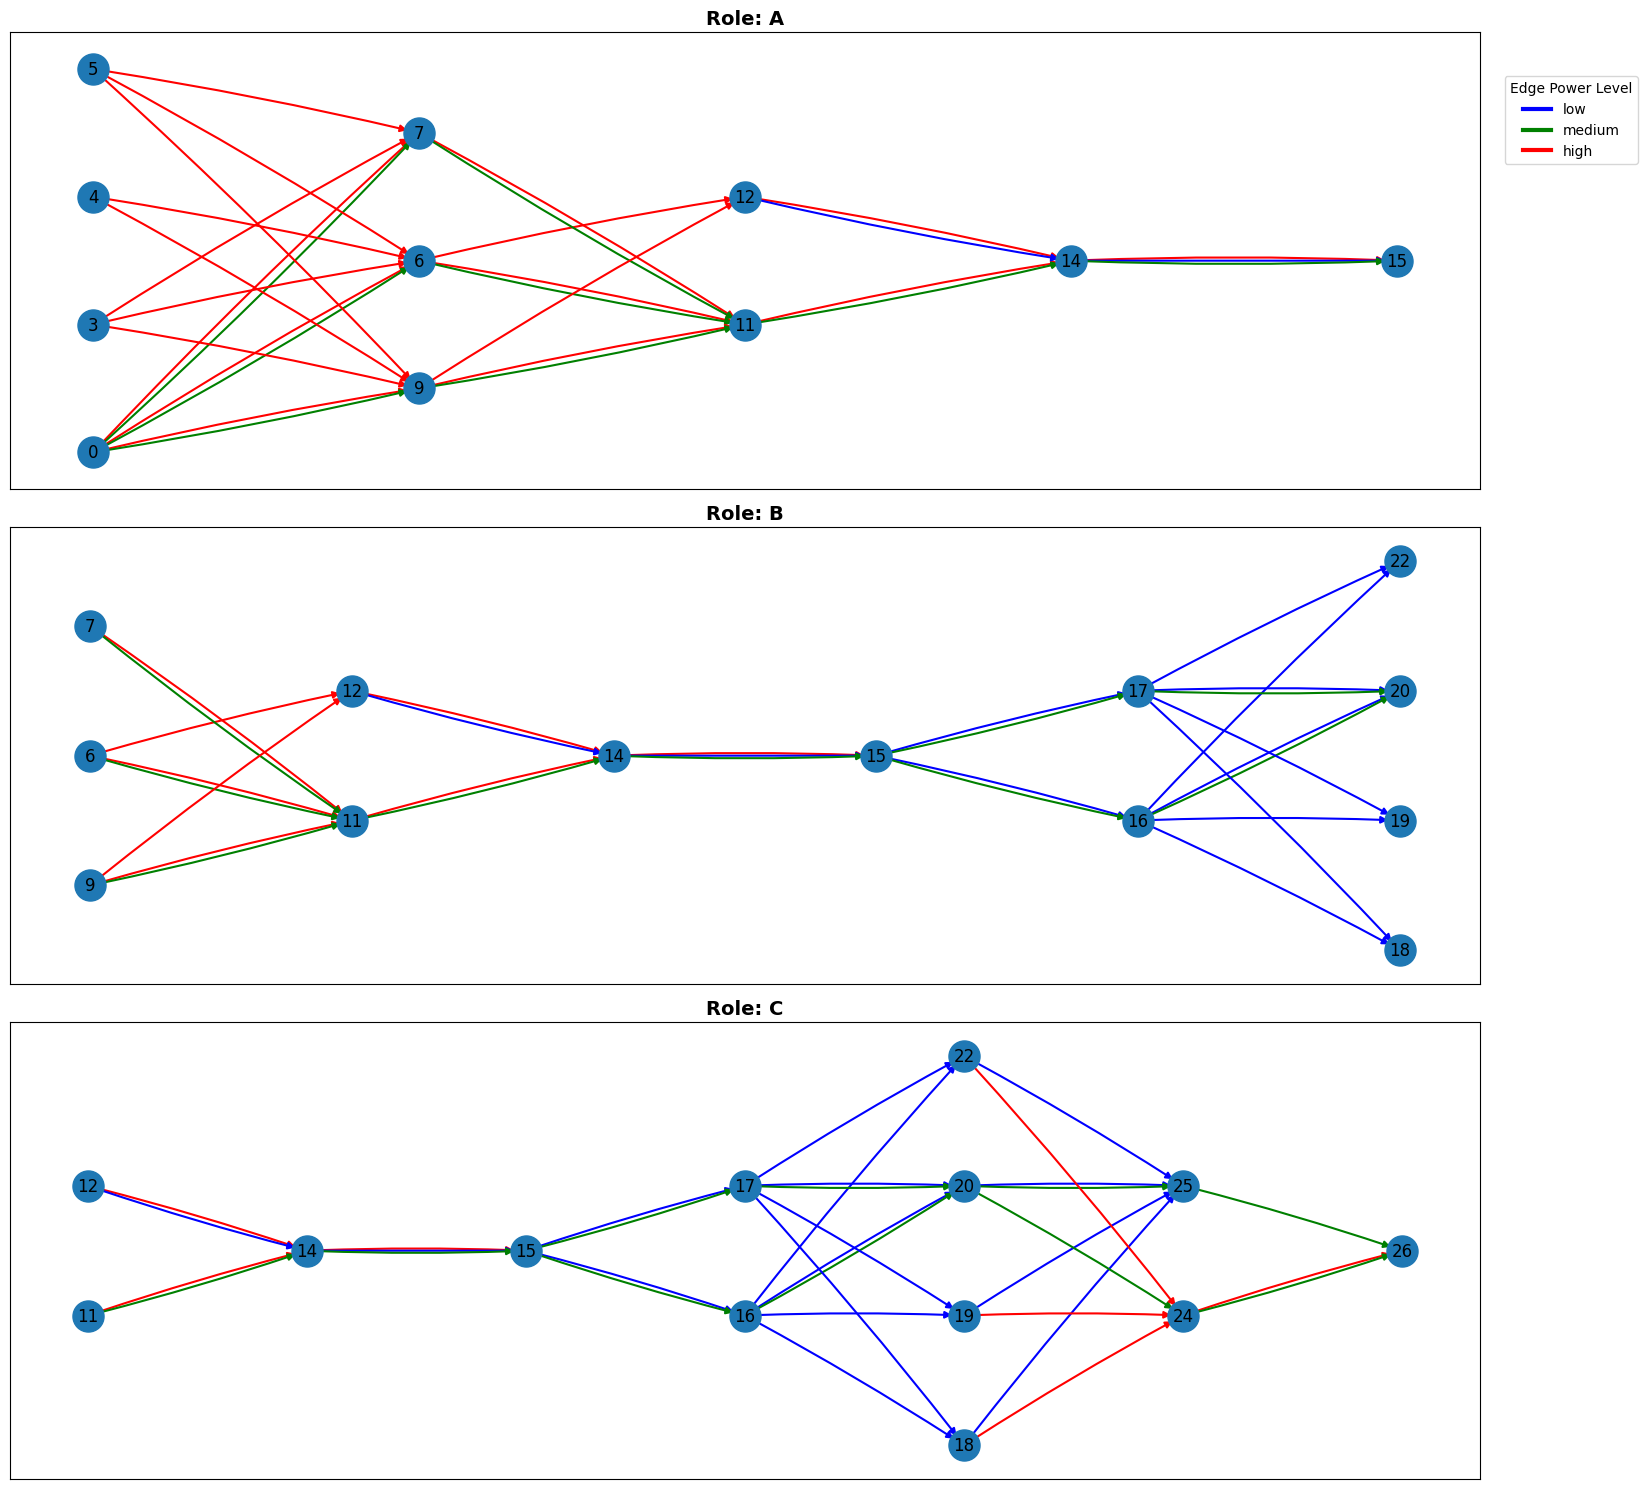

In [6]:
def sur_graph(G: nx.DiGraph) -> nx.DiGraph:
    h_nodes = []
    h_edges = []
    for n, d in G.nodes(data=True):
        if d['probability2'] > np.random.random():
            h_nodes.append(n)
    for u, v, d in G.edges(data=True):
        if u not in h_nodes or v not in h_nodes:
            continue
        if d['probability'] > np.random.random():
            h_edges.append((u,v))
    return G.edge_subgraph(h_edges)

# Success check
def success_eval(H: nx.DiGraph, sources: list, sink:int) -> bool:
    success = False
    for s in sources:
        if s not in H or sink not in H:
            continue
        if nx.has_path(H, s, sink):
            success = True
            break
    return success


H = sur_graph(G)
draw_role_graphs(H)

# Stochastic Simulation 1

There exists $G(N, E)$ with $p_i, d_i \ \forall \ i \in N, p_{(i,j)}, u_{(i,j)} \ \forall \ (i,j) \in E$ where $\boldsymbol{d}$, $\boldsymbol{u}$ are the vectors of node demands and  upper-bound capacities for $E \in G$. A monte-carlo simulation generates a uniformly distributed random number $r$. For each $x \in \{\{n \in N\} \cup \{e \in E\}\}, x \in G \iff x \geq r$. 

Upon the instantiation of $H \subseteq G$, for each MC run, results to the following tests are recorded:

1. Does there exist at least one path from origin nodes to the terminus (sink): $s_i \rightarrow t$?
2. What nodes are reachable for all origin nodes: $\exist \ s_i \rightarrow n_j \ \forall \ i \in N_0, \ \forall \ j \in N\backslash\{N_0\}$?
3. Which nodes fail when there does not exist $s_i \rightarrow t \ \forall \ i \in N_0$?
4. What is the count of independent remaining paths? 
5. What the lengths of all $s_i \rightarrow t$ paths?

## Aside: Types of Centrality

1. Degree centrality: What is the fraction of nodes each node is connected to?
2. Eigenvalue centrality: What is normalized fraction of nodes that each node is connect to given its predicessors?
3. Katz Centrality: Generalization of eigenvalue centrality to create a pareto frontier from degree centrality to eigenvalue centrality 
4. Load centrality: The fraction of all shortest paths that pass through each node
5. Laplacian centrality: The measurement of drop of laplacian energy of the graph when each node is removed. Note that $E_\mathcal{L}$

In [7]:
flow_value,_ = nx.maximum_flow(G, 0, 26, capacity='capacity')
print(f'Number of uninterdicted independent paths: {flow_value}')
degree_cent = nx.degree_centrality(G)
katz_cent = nx.katz_centrality(G, alpha=0.1, beta=3)
load_cent = nx.load_centrality(G)
lap_cent = nx.laplacian_centrality(G, normalized=True, nodelist=None, weight='weight', walk_type=None, alpha=0.95)



Number of uninterdicted independent paths: 5


In [ ]:


N = 1000
sink = 26
passthrough_count = 0
path_counts = []
path_lengths = []
layer_0_nodes = [n for n,d in G.nodes(data=True) if d['layer'] == 0]
reachable_count = {s: defaultdict(int) for s in layer_0_nodes}
reach_mat = np.zeros((len(layer_0_nodes), (len(G.nodes())-len(layer_0_nodes))))
capacity_count = {s: 0 for s in layer_0_nodes}
criticality = defaultdict(int)


for _ in trange(N):

    H = sur_graph(G)
    source_nodes = [n for n,d in H.nodes(data=True) if d['layer'] == 0]
    success = success_eval(H, source_nodes, sink)
    passthrough_count += success
    if sink in H:
        path_counts.append(sum(1 for s in source_nodes for _ in nx.all_simple_paths(H, s, sink)))
    # Reachability & flow measurement 
    source_path_lengths = []
    for i, s in enumerate(layer_0_nodes):
        if s not in H:
            #capacity_count[s].append(0)
            continue
        path_mat = list(nx.all_simple_edge_paths(G, 5, 15))
        param_mat = [[np.random.exponential(G.edges()[j]['probability']) for j in i] for i in path_mat]
        source_path_lengths.append([sum(i) for i in param_mat])
        reach_mat[i, s-len(layer_0_nodes)] += 1
        reachable = nx.descendants(H, s)
        for v in reachable:
            reachable_count[s][v-len(layer_0_nodes)] += 1 
            reach_mat[i, v-len(layer_0_nodes)] += 1
        if sink not in H:
            continue
        flow_value,_ = nx.maximum_flow(H, s, sink, capacity='capacity')
        capacity_count[s] += flow_value
    # Criticality
    path_lengths.append(source_path_lengths)
    if not success:
        for u,v,d in G.edges(data=True):
            if (u,v) not in H.edges():
                criticality[(u,v)] += 1

    
print(f'P(success): {passthrough_count/N}')
reachability_prob = {s: {v: cnt / N for v, cnt in reachable_count[s].items()}for s in layer_0_nodes}
print(f'Reachability: \n{reachability_prob}')
print(f'Criticality: \n{dict(criticality)}')
print(f'Max flow: \n{capacity_count}')

100%|██████████| 1000/1000 [00:12<00:00, 78.72it/s]

P(success): 0.586
Reachability: 
{0: {1: 0.428, 3: 0.515, 6: 0.544, 7: 0.432, 8: 0.695, 9: 0.683, 10: 0.514, 11: 0.675, 13: 0.574, 14: 0.519, 15: 0.45, 16: 0.416, 17: 0.438, 18: 0.624, 19: 0.459, 20: 0.41, 0: 0.612, 5: 0.609, 12: 0.374, 2: 0.313, 4: 0.316}, 1: {0: 0.514, 3: 0.697, 6: 0.666, 7: 0.535, 8: 0.848, 9: 0.834, 10: 0.624, 11: 0.818, 13: 0.693, 14: 0.644, 15: 0.542, 16: 0.508, 17: 0.532, 18: 0.756, 19: 0.566, 20: 0.502, 2: 0.477, 4: 0.488, 5: 0.749, 12: 0.453, 1: 0.659}, 2: {0: 0.604, 3: 0.416, 6: 0.554, 7: 0.419, 8: 0.701, 9: 0.689, 10: 0.511, 11: 0.676, 13: 0.579, 14: 0.535, 15: 0.444, 16: 0.415, 17: 0.432, 18: 0.628, 19: 0.464, 20: 0.418, 2: 0.357, 4: 0.361, 5: 0.603, 12: 0.361, 1: 0.408}, 3: {0: 0.702, 1: 0.545, 2: 0.328, 3: 0.608, 4: 0.492, 5: 0.704, 6: 0.63, 7: 0.51, 8: 0.798, 9: 0.787, 10: 0.59, 11: 0.773, 13: 0.662, 14: 0.602, 18: 0.712, 19: 0.535, 12: 0.425, 16: 0.474, 17: 0.494, 20: 0.484, 15: 0.518}, 4: {0: 0.654, 1: 0.587, 3: 0.459, 6: 0.659, 7: 0.511, 8: 0.845, 9: 

In [18]:
sum(np.isnan(reach_mat))

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

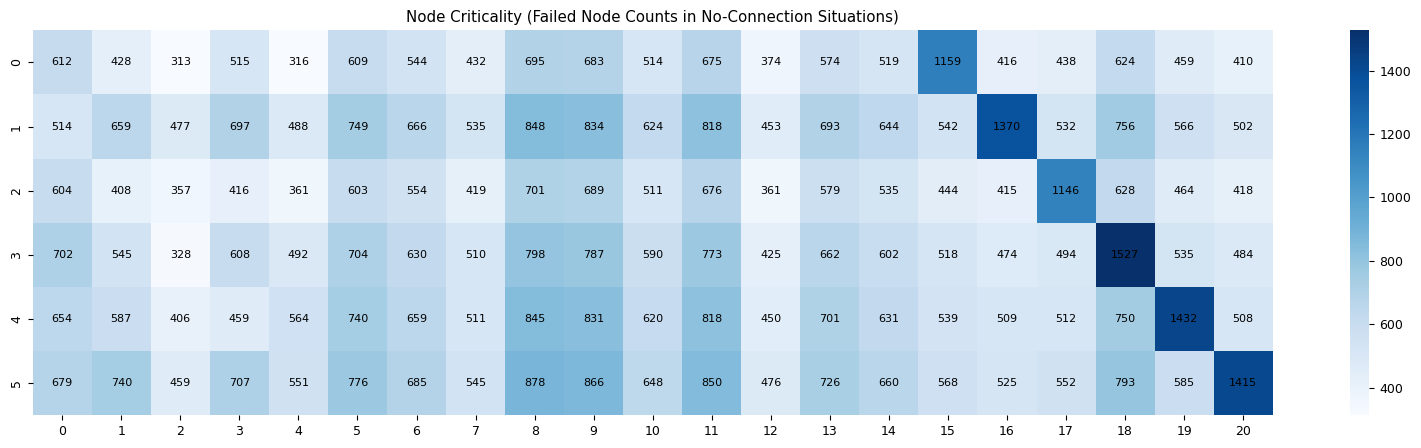

In [40]:
def shift_ticks(ax, shift):
    ticks = ax.get_xticks()
    ax.set_xticks(ticks)
    ax.set_xticklabels([str(i + shift) for i in range(len(ticks))])

import seaborn as sns

fig, ax = plt.subplots(figsize=(20, 5))
plt.title('Node Criticality (Failed Node Counts in No-Connection Situations)')
sns.heatmap(reach_mat, annot=False, cmap='Blues', ax=ax)

for i in range(reach_mat.shape[0]):
    for j in range(reach_mat.shape[1]):
        ax.text(j + 0.5, i + 0.5, f"{reach_mat[i, j]:.0f}",
                ha='center', va='center', fontsize=8)

plt.show()


# Sensitivity Analysis

## Case 1: Sensitivity analysis with continuous objective functions 
Given $G(N, E)$ and a function $f: \mathbb{R}^{|N|+|E|} \mapsto \mathbb{R}$, it is of interest to calculate $\frac{\partial}{\partial x_i}f(\boldsymbol{x}) \ \forall \ i \in S \subseteq \{N \cup E\}$. As an example, consider the graph $G$ with four nodes connected as a diamond, each with edge weights assigned via random variates of an exponential distribution. If every edge is assigned an attribute "class" for each edge, then $\frac{\partial}{\partial x_i}$ of each class with to the shortest path, then the following statements are true:

1. If $(u,v) \in p^*$, then $\frac{\partial}{\partial(u,v)} = 1$
2. If $(u,v) \notin p^*$, then $\frac{\partial}{\partial(u,v)} = 0$

This is because the length of the shortest path is determined by:

 $\displaystyle\sum_{e \in E} w_e\ell_e: w_e\in\{0,1\}, \ell_e \in \mathbb{R}$, 
 
 a linear combination of path lengths where the weight $(w)$ of each path is 1, and where the length of each path is a stochastic parameter.  


However, this technique is only usable over metrics that are fully differentiable. Because path length is a linear function, sensitivity analysis along a path reduces to the number of components subject to the input parameter change $\sum w_i \frac{\partial}{\partial x_i}: i \in \boldsymbol{\theta}$, the changed edge/node set. The MC iterations in the simulation inherently capture changes in the shortest path, so that any non-differentiable components of the full stochastic function $f$ is properly accounted for. 



In [11]:
from collections import defaultdict
from tqdm import trange

def create_toy_graph():
    G = nx.DiGraph()
    G.add_nodes_from([i for i in range(4)])
    G.add_edges_from([(0, 1), (0,2), (1,3), (2, 3)])
    for e in G.edges():
        G.edges()[e]['w'] = 1
        G.edges()[e]['class'] = e
    return G

def attrib_sens(G, s=0, t=3, attribute_name='class', N=20_000, step_size=1e-6):
    seq = np.random.SeedSequence(123)
    class_edges = defaultdict(list)
    for u,v,d in G.edges(data=True):
        class_edges[d[attribute_name]].append((u,v))
    mat = np.zeros((N, len(class_edges)+1))
    for i in trange(N):
        rng = np.random.default_rng(seq.spawn(1)[0])
        nx.set_edge_attributes(G, {(u,v): rng.exponential(d['w']) for u,v,d in G.edges(data=True)}, name='w_realized')
        mat[i, 0] = nx.shortest_path_length(G, s, t, weight='w_realized')
        for j, (clss, edges) in enumerate(class_edges.items()):
            for u, v in edges:
                G[u][v]['w_realized'] += step_size
            mat[i, j+1] = nx.shortest_path_length(G, s, t, weight='w_realized')
            for u, v in edges:
                G[u][v]['w_realized'] -= step_size
    dell_mat = (mat[:, 1:]-mat[:, [0]])/step_size
    return dell_mat, mat[:, 0]

T = create_toy_graph()
attrib_sens(T)





100%|██████████| 20000/20000 [00:02<00:00, 7866.20it/s]


(array([[1., 0., 1., 0.],
        [0., 1., 0., 1.],
        [1., 0., 1., 0.],
        ...,
        [1., 0., 1., 0.],
        [0., 1., 0., 1.],
        [0., 1., 0., 1.]]),
 array([0.85381172, 1.47819433, 1.65662586, ..., 4.57410533, 2.28127969,
        1.13166428]))

## Case 2: Sensitivity analysis with large discontinuities 

For all $x_i \in \{N \cup E\}$, there a probability $p_i$ for each $x_i$. A graph $H$ is constructed such that $e \in E_H$ if $p_e, p_u, \& \ p_v \geq r: e = (u,v), u,v \in N_H$. The quantitative method to establish $\frac{\partial}{\partial x_i}$ in case 1 is  determined by $\frac{f(x) - f(x+\varepsilon)}{\varepsilon}$. In simulations where edges are determined by $p_i \geq r$, then the state of the graph only changes when $p_i < r$ and $p_i + \varepsilon \geq r$ with probability $\approx \frac{1}{\varepsilon}$. To get a reasonable MC evaluation $N \cdot \frac{1}{\varepsilon}$ simulations, which is not scalable, nor reasonable to consider, therefore, new analysis is required. 

$G(N,E)$ through MC sampling has nodes and edges removed from the graph $\rightarrow H_k(N', E') \ \forall k \in N$ simulations. The method to determine relative importance within the graph is to consider if the removal of an edge disconnects the graph, for graphs that are previously connected. Recall that edge criticality is a measurement of the expectation that an edge fails given the graph is not connected. This sensitivity analysis is conducted over the sub-sample of successful $s\rightarrow t$ paths, which were neglected in the initial simulation. This way, there is a measurement of edge influence in the context of both cases of connectivity. 

In $H_i(N', E')$, if the maximum-flow of the graph is greater than $1$, then no edges are counted as influential. This is because any removed edge will still result in graph connectivity, as at maximum, max-flow will only decrease by $1$ unit. 



In [5]:
def estimate_edge_influence(G, s, t, N=int(1000), seed=123):
    
    rng = np.random.default_rng(seed)
    edges = list(G.edges())
    m = len(edges)

    edge_index = {e: i for i, e in enumerate(edges)}

    influence = np.zeros(m, dtype=float)
    connected_count = 0
    N = int(1000)
    for _ in trange(N):

        # --- sample active edges ---
        active = []

        for u, v, d in G.edges(data=True):
            prob = d['probability']
            if np.random.random() < prob:
                active.append((u, v))

        H = nx.DiGraph()
        H.add_edges_from(active)

        # --- connectivity check ---
        if s not in H or t not in H:
            continue
        if not nx.has_path(H, s, t):
            continue

        connected_count += 1

        # nodes reachable from s
        reachable = nx.descendants(H, s)

        H_sub = H.subgraph(reachable)

        # --- compute bridges (cheap on small subgraph) ---
        bridges = list(nx.bridges(H_sub.to_undirected()))

        for e in bridges:
            if e in edge_index:
                influence[edge_index[e]] += 1

    # normalize
    influence /= N
    return influence, connected_count / N

influ_m, score =  estimate_edge_influence(G, 0, 26)


100%|██████████| 1000/1000 [00:01<00:00, 862.11it/s]


In [7]:
G.nodes()[0]

{'layer': 0,
 'demand': -3,
 'probability1': 0.7029766909818379,
 'probability2': 0.9479182360270755,
 'cost': 2,
 'loc_region': (-5, 5),
 'loc': (-3.9506152113300432, -3.6603689021273214),
 'power': ['medium', 'low'],
 'role': ['A']}

In [8]:
G.edges()[(0,6)]

{'role': 'A',
 'power': 'medium',
 'capacity': 4,
 'probability': 0.9409592386160044,
 'performance': 73.78313179840123,
 'cost': 4.79333454677171}

# Interdiction Games

Suppose there exist a graph $G(N, E)$ with the following parameters available:

- Demand: $d_i \in \{0, 1\}$
- Probabilities: $p_{i, k} \ \forall \ k \in K_1$ 
- Cost: $c_i$
- Location and location space: $ \ell \in \mathbb{R} \times \mathbb{R}; \mathcal{L} \in [\boldsymbol{\ell}_{LB} \leq \boldsymbol{x} \leq \boldsymbol{\ell}_{UB}]$
- categorical features: $\mathcal{C}_{i,k} \ \forall \ k \in K_3$

For all $i \in N$

- Capacity: $u_{(i,j)}$
- Probabilities: $p_{(i,j), k} \ \forall \ k \in K_2$
- Performance: $w_{(i,j)}$
- Cost: $c_{(i,j)}$ 
- categorical features: $\mathcal{C}_{(i, j),k} \ \forall \ k \in K_4$

For all $(i,j) \in E$

## Game:
There are two players, $p_1, p_2$, where $p_1$ is responsible for the security of a cloud-based banking system. The banking system has multiple features to ensure that it remains secure. For each node and edge in the security system, graph objects are either A. Sensors, B. Task enforcement, or C. response. Because this is a cloud based system, not all elements of the security system are interconnected and have to pass through a chain, where task enforcement generates a response from security, that then outputs a response plan. 

The goal of $p_2$ is to steal from the bank and evade response from the security network. This can be done through interdiction of nodes or through disabling communication schemes of the cloud-based devices. With each type of interdiction is an associated resource cost, which $p_2$ is limited by. $p_1$ in this setting is tasked with the objective of maximizing flow over the network, with the goal of maximizing detection and execution of a task. Therefore, given this scheme, the goal $p_2$ is to minimize the flow over the network, where a maximum flow of $0 \Rightarrow$ A full bank robbery. 

## Modeling: 

Player 1: 
- $x_{(i,j)} \in \mathbb{R}$ is the flow assigned from on edge $(i,j) \in E$

Player 2: 
- $z^E_{i, j)} \in \{0,1\}$ is a decision to interdict an edge $(i,j) \in E$
- $z^N_i \in \{0,1\}$ is a decision to interdict a node $i \in N$
- $y_{(x,y)} \in \mathbb{R} \times \mathbb{R}$ is the location of where a heist is to occur. 

Zero-sum objective: 

$\displaystyle F(\boldsymbol{x}) = \sum_{(i,j) \in E: (i,j) \in S} x_{(i,j)} - \sum_{(i,j) \in E: (i,j) \in T} x_{(i,j)}$

### Objective Function:
$\displaystyle \sum_{(i,j) \in E: (i,j) \in S} x_{(i,j)}$ is the total flow out from source nodes. Source nodes are nodes that potentially have first-observation capabilities of a heist occurring. 

$\displaystyle \sum_{(i,j) \in E: (i,j) \in T} x_{(i,j)}$ is the total flow in to final response nodes. Final response nodes receiving demand will signify that a heist is stopped. 






### Validity of $F(x)$/ Constructing constraints:

#### Graph construction: 
Given a fully unconstrained graph, then the least upper bound for $F(\boldsymbol{x})$ is $\infty$. To accurately account for detection, demand $d_i = 1$ is assigned when a heist begins to each node that is capable and responsible for detection in their AOR. Once a heist begins, based on the current constraint system, over-flooding the sensing-system with flow results in an objective function value of $F^*(\boldsymbol{x}) = \infty$. To constrain this objective function value, flow out of $S$ is limited to 

$d_i: \left(\displaystyle\sum_{(i,j) \in E: i \in S}x_{(i,j)}\right) \leq d_i$,

ensuring that a heist is registered as "demand for flow", and that there is a commodity to pass through the network. Now that flow is established, it has to work its way through the network, being passed from node to node. "Demand" is the starting state of a node, where "flow" is the information passed from $i \rightarrow j$. Once demand from $n \in S$ is established, then demand-reception preference can be established by $p_1$ where $\sum d_i \ \forall \ n_i \in T - \sum d_j \ \forall \ n_j \in S = 0$, where $d_i \in \mathbb{R}, d_j \in \mathbb{N}$. $d_i$ is then interpreted as probabilistic, due to the stochastic nature of the graph, whereas demand can be assigned by the auxiliary decisions of $p_2$. 

Flow decisions are balanced by:
$ \displaystyle\sum_{(i,j) \in E} x_{(i,j)} - x_{(j,i)} = d_i + \lambda_i: \lambda_i$ is the lost demand due to node or edge failure. If $\lambda_i$ did not exist, then disconnected graphs would not be a feasible result of the model, and therefore $p_2$ success could not be accounted for. 

#### Monte Carlo constraints:

Probabilistic parameters exist with respect to:

$p_1$ variables:
- Edge functionality for all $k \in K_1$
- Node functionality for all $k \in K_2$

$p_2$ decisions:
- Edge categorical features for all $k \in K_3$
- Node categorical features for all $k \in K_4$